In [ ]:
# data checking (exploratory data analysis). 
import pandas as pd

gen1 = pd.read_csv('../data/Plant_1_Generation_Data.csv')
wea1 = pd.read_csv('../data/Plant_1_Weather_Sensor_Data.csv')

# Convert DATE_TIME strings to datetime so merge and plotting work correctly
gen1['DATE_TIME'] = pd.to_datetime(gen1['DATE_TIME'], format='%d-%m-%Y %H:%M')
wea1['DATE_TIME'] = pd.to_datetime(wea1['DATE_TIME'], format='%Y-%m-%d %H:%M:%S')

df = pd.merge(gen1, wea1, on='DATE_TIME', how='inner')

print(gen1.describe())
print(gen1.shape)
print(gen1.isnull().sum())

                           DATE_TIME   PLANT_ID      DC_POWER      AC_POWER  \
count                          68778    68778.0  68778.000000  68778.000000   
mean   2020-06-01 08:02:49.458256896  4135001.0   3147.426211    307.802752   
min              2020-05-15 00:00:00  4135001.0      0.000000      0.000000   
25%              2020-05-24 00:45:00  4135001.0      0.000000      0.000000   
50%              2020-06-01 14:30:00  4135001.0    429.000000     41.493750   
75%              2020-06-09 20:00:00  4135001.0   6366.964286    623.618750   
max              2020-06-17 23:45:00  4135001.0  14471.125000   1410.950000   
std                              NaN        0.0   4036.457169    394.396439   

        DAILY_YIELD   TOTAL_YIELD  
count  68778.000000  6.877800e+04  
mean    3295.968737  6.978712e+06  
min        0.000000  6.183645e+06  
25%        0.000000  6.512003e+06  
50%     2658.714286  7.146685e+06  
75%     6274.000000  7.268706e+06  
max     9163.000000  7.846821e+06  


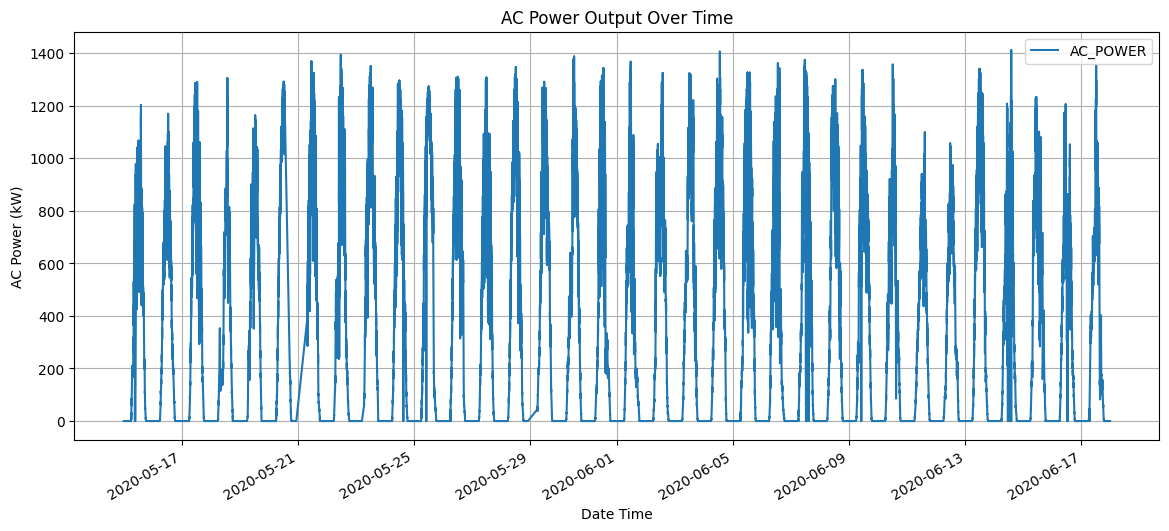

In [ ]:
# AC POWER output over time 
import matplotlib.pyplot as plt

df.plot(x='DATE_TIME', y='AC_POWER', figsize=(14, 6)) #df.plot is inside the pandas library, not matplotlib, so we use plt for the rest of the formatting
plt.title('AC Power Output Over Time')
plt.xlabel('Date Time')
plt.ylabel('AC Power (kW)')
plt.grid()
plt.show()

Text(0.5, 1.0, 'Average output by hour of day')

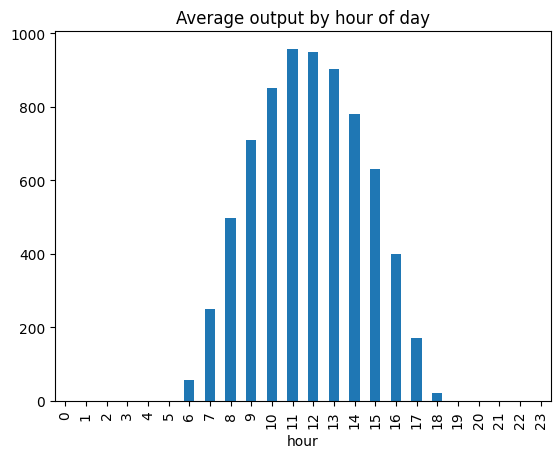

In [ ]:
# output trend by hour of day
df['hour'] = df['DATE_TIME'].dt.hour
df.groupby('hour')['AC_POWER'].mean().plot(kind='bar')
plt.title('Average output by hour of day')

Text(0.5, 1.0, 'Irradiation vs AC Power')

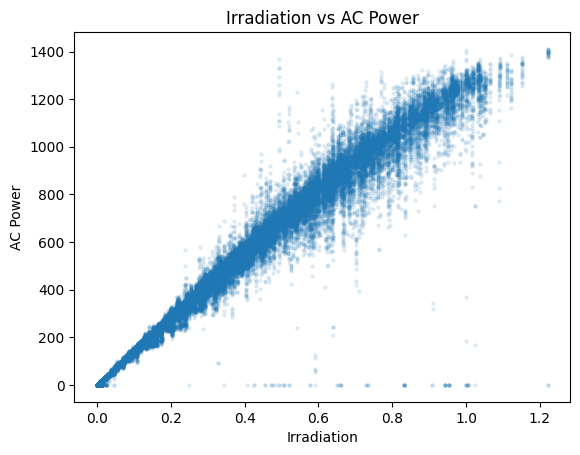

In [8]:
# irradiance vs output
plt.scatter(df['IRRADIATION'], df['AC_POWER'], alpha=0.1, s=5)
plt.xlabel('Irradiation')
plt.ylabel('AC Power')
plt.title('Irradiation vs AC Power')

at very high temperatures, output slightly drops. This is the panel efficiency loss 


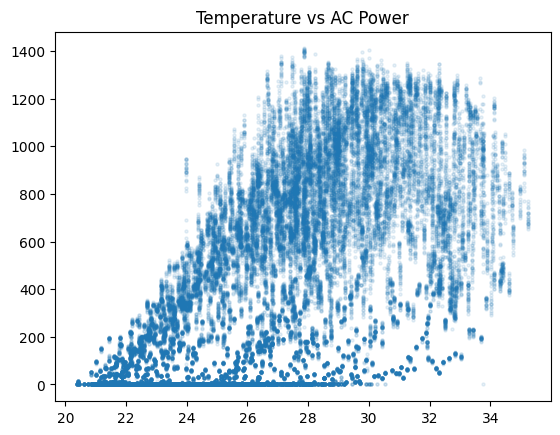

In [11]:
# temperature vs output
plt.scatter(df['AMBIENT_TEMPERATURE'], df['AC_POWER'], alpha=0.1, s=5)
plt.title('Temperature vs AC Power')
print("at very high temperatures, output slightly drops. This is the panel efficiency loss ")

Text(0.5, 1.0, 'Distribution of AC Power values')

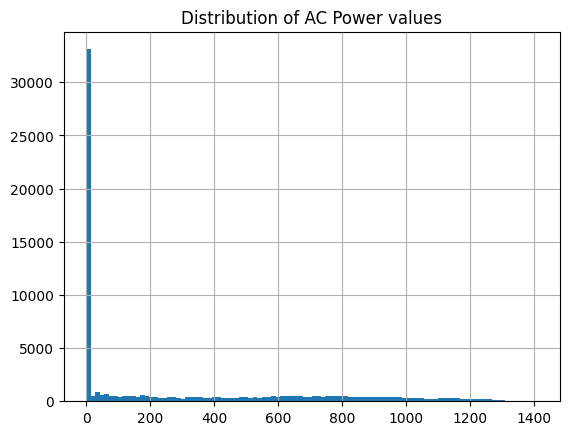

In [ ]:
#Look for values that are impossibly high or negative. These are sensor errors and need to be removed

df['AC_POWER'].hist(bins=100)
plt.title('Distribution of AC Power values')

Text(0.5, 1.0, 'Feature correlations')

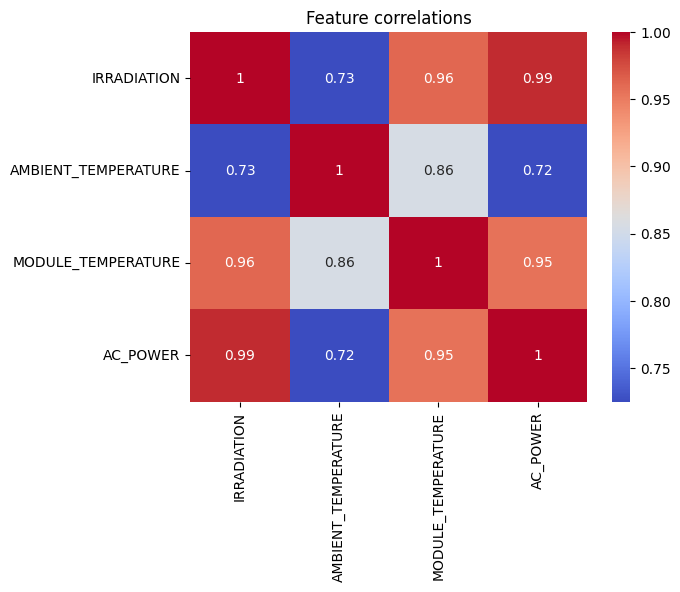

In [ ]:
import seaborn as sns

corr = df[['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'AC_POWER']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Feature correlations')

# This tells us that the most important features for predicting output are irradiation and module temperature, which makes physical sense. Ambient temperature is less correlated, but still has some relationship with output.